# LDS7003M-AI & ML

# Linear Regression 

Linear regression is a fundamental statistical and machine learning technique used for modeling the relationship between a dependent variable (also called the target) and one or more independent variables (also called predictors or features). The primary goal of linear regression is to find a linear relationship that best describes the data. This linear relationship is typically represented as a straight line (hence "linear") in a two-dimensional space, but it can also involve higher-dimensional hyperplanes in multiple linear regression.


# Seminar 

This Notebook provides the data and code for the simple linear regression illustrated in the slides, i.e. the housing price data. This is an artificial dataset constructed just to illustrate how to go about implementing simple linear regression in Python.

To start with, we use arrays to store the data and then we plot the data. Note that we need some import statements since we are using the Python libraries Matplotlib and Numpy. 

the __.T__ operator is used to transpose a NumPy array, changing its orientation from rows to columns or vice versa, which can be useful for specific mathematical operations and data manipulations.

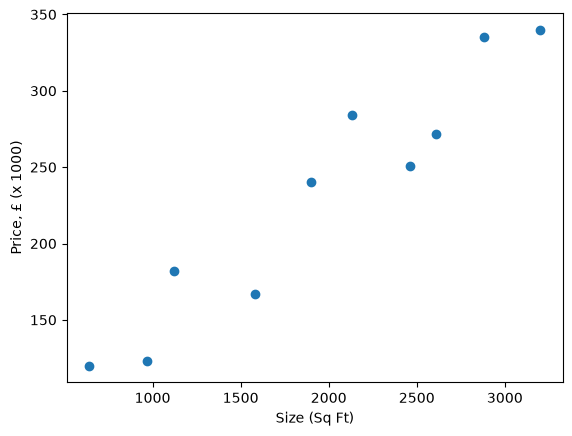

In [1]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([[640, 970, 1120, 1580, 1900, 2130, 2460, 2610, 2880, 3200]]).T
y = np.array([[120, 123, 182, 167, 240, 284, 251, 272, 335, 340]]).T

plt.scatter(x, y) 
plt.xlabel('Size (Sq Ft)')
plt.ylabel('Price, £ (x 1000)')
plt.show()

From the plot it looks like there is an approximate linear dependence, so it seems reasonable to apply linear regression.

We will be using the <a href="https://scikit-learn.org/stable/index.html"> **Scikit-learn library** </a>a lot in this module as it is very widely used for machine learning in Python. 

Before apply linear regression, we will first split the data into training and test sets using the function <a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html#sklearn.model_selection.train_test_split">*train_test_split*</a> from the *sklearn.model_selection* module in Sci-kit learn (*sklearn*).

*test_size* specifies the proportion of the data to be used for testing.<br>
*random_state* specifies how test cases are randomly selected. Setting it to zero is just to ensure you get the same test cases as used in the lecture notes.

**Note: since there are only 10 instances in our dataset it doesn't make a lot of sense to split it into training and test sets, so it is just to illustrate the idea.**

In [2]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 0)

print(x_test)
print(y_test)

[[1120]
 [2880]]
[[182]
 [335]]


Now we will carry out linear regression on the training set. First, import the *LinearRegression* class and use it to create an object called 'regr'. Then train the model using 'fit'. This gives us a model of the form $$ Y = aX + b$$ where $a$ and $b$ are the intercept and coefficient respectively. 

In [3]:
from sklearn.linear_model import LinearRegression

regr = LinearRegression()

# Train the model
regr.fit(x_train, y_train)

# Display the coefficients
print('Intercept: \n', regr.intercept_)
print('Coefficient: \n', regr.coef_)

Intercept: 
 [51.35627658]
Coefficient: 
 [[0.08948675]]


Now that we have obtained our regression model, we can plot the line over the whole range of the data. We can also plot the training and test data.

In [4]:
# Specify the mininmum and maximum values of x to display the line of best fit
x_range = np.array([min(x), max(x)])

# Now use the regression model to obtain the predictions for the lowest and highest x values
y_pred_range = regr.predict(x_range)


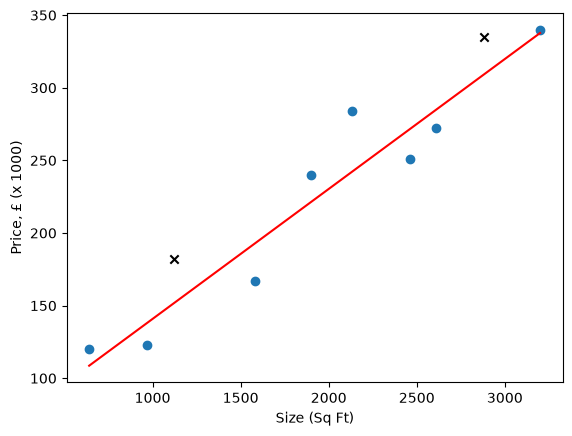

In [5]:
# Plot the line along with the training data
plt.plot(x_range, y_pred_range, color='red')

# Plot the training data
plt.scatter(x_train, y_train)

# Plot the test data
plt.scatter(x_test, y_test,marker='x',color='black') 

plt.xlabel('Size (Sq Ft)')
plt.ylabel('Price, £ (x 1000)')
plt.show()

Finally, we can evaluate the model by calculating its predictions for the test set using the function *predict* and then calculating the $R^2$ value. The closer $R^2$ is to 1, the better. 

In [6]:
# Predicting the Test set results
y_pred = regr.predict(x_test)

print(y_test)
print(y_pred)

[[182]
 [335]]
[[151.58143874]
 [309.07812213]]


In [7]:
from sklearn.metrics import r2_score

print('Coefficient of determination, R^2: %.3f'
      % r2_score(y_test, y_pred))

Coefficient of determination, R^2: 0.864


RMSE (Root Mean Squared Error): Measures the average magnitude of errors between predicted and true values. It squares the differences between predicted and true values, averages them and then takes the square root. 

MAE (Mean Absolute Error): Measures the average absolute magnitude of errors between predicted and true values. It takes the average of the absolute differences between predicted and true values. MAE treats all errors equally, regardless of their magnitude. Lower values are better.



In [8]:
from sklearn.metrics import mean_squared_error, mean_absolute_error


rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE: {rmse:.3f}')


RMSE: 28.260


In [9]:
mae = mean_absolute_error(y_test, y_pred)
print(f'MAE: {mae:.3f}')


MAE: 28.170
